**Multiple Linear Regression**
- Gradient Descent Manual Implementation
- Normal Equation Implementation
- Implemation through Scikit-Learn

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
x = np.loadtxt("ex3Data/ex3x.dat", dtype=np.float32)
y = np.loadtxt("ex3Data/ex3y.dat", dtype=np.float32)

In [5]:
x, y

(array([[2.104e+03, 3.000e+00],
        [1.600e+03, 3.000e+00],
        [2.400e+03, 3.000e+00],
        [1.416e+03, 2.000e+00],
        [3.000e+03, 4.000e+00],
        [1.985e+03, 4.000e+00],
        [1.534e+03, 3.000e+00],
        [1.427e+03, 3.000e+00],
        [1.380e+03, 3.000e+00],
        [1.494e+03, 3.000e+00],
        [1.940e+03, 4.000e+00],
        [2.000e+03, 3.000e+00],
        [1.890e+03, 3.000e+00],
        [4.478e+03, 5.000e+00],
        [1.268e+03, 3.000e+00],
        [2.300e+03, 4.000e+00],
        [1.320e+03, 2.000e+00],
        [1.236e+03, 3.000e+00],
        [2.609e+03, 4.000e+00],
        [3.031e+03, 4.000e+00],
        [1.767e+03, 3.000e+00],
        [1.888e+03, 2.000e+00],
        [1.604e+03, 3.000e+00],
        [1.962e+03, 4.000e+00],
        [3.890e+03, 3.000e+00],
        [1.100e+03, 3.000e+00],
        [1.458e+03, 3.000e+00],
        [2.526e+03, 3.000e+00],
        [2.200e+03, 3.000e+00],
        [2.637e+03, 3.000e+00],
        [1.839e+03, 2.000e+00],
        

In [6]:
x.shape[0], y.shape[0]

(47, 47)

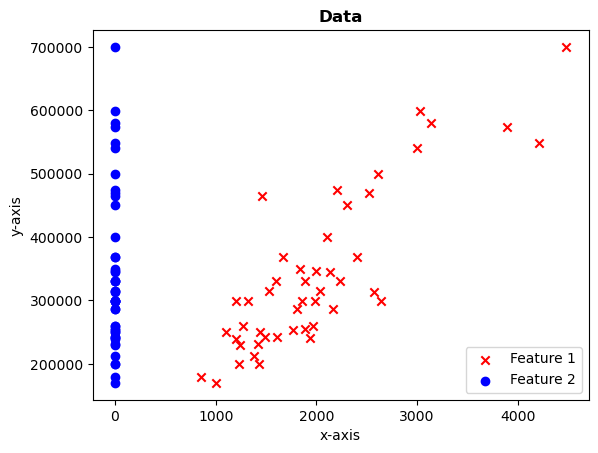

In [ ]:
plt.scatter(x[:, 0], y, marker='x', c='r', label = "Feature 1")
plt.scatter(x[:, 1], y, marker='o', c='b', label = "Feature 2")
plt.title("Data", fontweight="bold")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.legend()
plt.show()

**First column: bias (intercept), next columns: input features**

In [9]:
X = np.ones((x.shape[0], 3))

In [11]:
X[:, 1] = x[:, 0]
X[:, 2] = x[:, 1]
X

array([[1.000e+00, 2.104e+03, 3.000e+00],
       [1.000e+00, 1.600e+03, 3.000e+00],
       [1.000e+00, 2.400e+03, 3.000e+00],
       [1.000e+00, 1.416e+03, 2.000e+00],
       [1.000e+00, 3.000e+03, 4.000e+00],
       [1.000e+00, 1.985e+03, 4.000e+00],
       [1.000e+00, 1.534e+03, 3.000e+00],
       [1.000e+00, 1.427e+03, 3.000e+00],
       [1.000e+00, 1.380e+03, 3.000e+00],
       [1.000e+00, 1.494e+03, 3.000e+00],
       [1.000e+00, 1.940e+03, 4.000e+00],
       [1.000e+00, 2.000e+03, 3.000e+00],
       [1.000e+00, 1.890e+03, 3.000e+00],
       [1.000e+00, 4.478e+03, 5.000e+00],
       [1.000e+00, 1.268e+03, 3.000e+00],
       [1.000e+00, 2.300e+03, 4.000e+00],
       [1.000e+00, 1.320e+03, 2.000e+00],
       [1.000e+00, 1.236e+03, 3.000e+00],
       [1.000e+00, 2.609e+03, 4.000e+00],
       [1.000e+00, 3.031e+03, 4.000e+00],
       [1.000e+00, 1.767e+03, 3.000e+00],
       [1.000e+00, 1.888e+03, 2.000e+00],
       [1.000e+00, 1.604e+03, 3.000e+00],
       [1.000e+00, 1.962e+03, 4.00

**Feature Scaling**
- Z-score normalization

In [12]:
X[:, 1] = (X[:, 1] - np.mean(X[:, 1]))/np.std(X[:, 1])
X[:, 2] = (X[:, 2] - np.mean(X[:, 2]))/np.std(X[:, 2])

y = (y - np.mean(y)) / np.std(y)

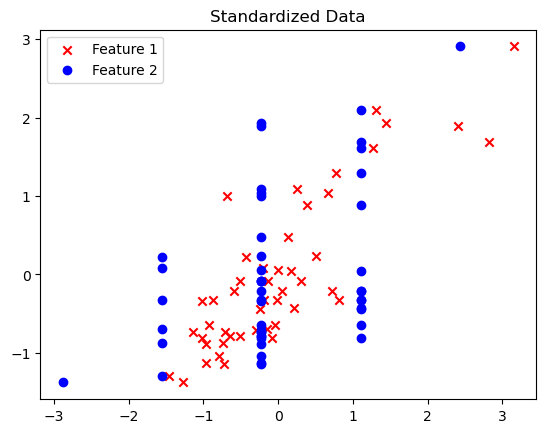

In [13]:
plt.scatter(X[:, 1], y, marker='x', c='r', label="Feature 1")
plt.scatter(X[:, 2], y, marker='o', c='b', label="Feature 2")
plt.title("Standardized Data")
plt.legend()
plt.show()

In [14]:
def hypothesis(x, w):
    return np.dot(x, w)

In [15]:
def cost(x, y, w):
    return 1/(2*x.shape[0]) * np.sum(hypothesis(x, w) - y)**2

In [16]:
def gradient(x, y, w):
    return 1/x.shape[0] * x.T.dot(hypothesis(x, w) - y)

In [17]:
w = np.array([0, 0, 0])
costVal = []
epochs = []

for i in range(10000):
    costVal.append(cost(X, y, w))
    w = w - 0.0003 * gradient(X, y, w)
    epochs.append(i)

In [18]:
w

array([2.73400978e-08, 7.55655814e-01, 6.82227128e-02])

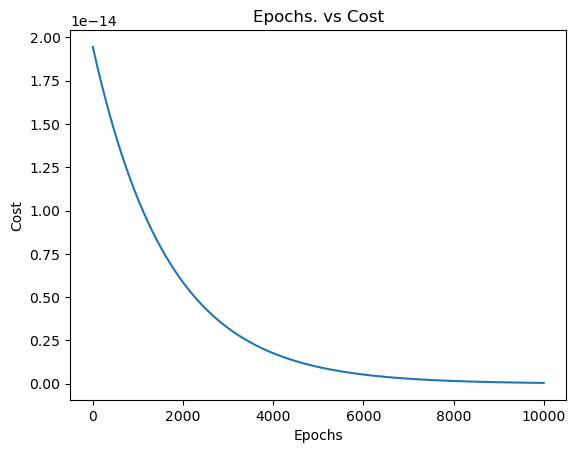

In [19]:
plt.plot(epochs, costVal)
plt.title("Epochs. vs Cost")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.show()

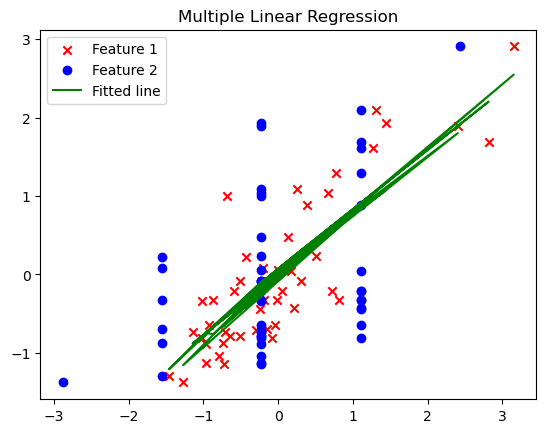

In [29]:
plt.scatter(X[:, 1], y, marker='x', c='r', label="Feature 1")
plt.scatter(X[:, 2], y, marker='o', c='b', label="Feature 2")
plt.plot(X[:, 1], hypothesis(X, w), c='g', label="Fitted line")
plt.title("Multiple Linear Regression")
plt.legend()
plt.show()

---

**Normal Equation Implementation**

In [ ]:
# 1st Implementation
theta = np.linalg.inv(X.T @ X) @ X.T @ y

In [32]:
theta

array([ 2.87719230e-08,  8.84765964e-01, -5.31788185e-02])

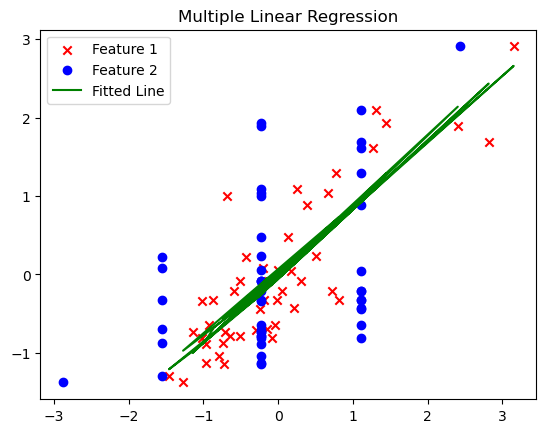

In [33]:
plt.scatter(X[:, 1], y, marker='x', c='r', label="Feature 1")
plt.scatter(X[:, 2], y, marker='o', c='b', label="Feature 2")
plt.plot(X[:, 1], hypothesis(X, theta), c='g', label="Fitted Line")
plt.title("Multiple Linear Regression")
plt.legend()
plt.show()

In [35]:
# 2nd Implementation
theta = np.linalg.pinv(np.dot(X.T, X)).dot(np.dot(X.T, y))

In [36]:
theta

array([ 2.87719230e-08,  8.84765964e-01, -5.31788185e-02])

In [37]:
# 3rd implementation
theta = np.linalg.pinv(X.T.dot(X)).dot(X.T.dot(y))

In [38]:
theta

array([ 2.87719230e-08,  8.84765964e-01, -5.31788185e-02])

---
**Implementation through Scikit-Learn**

In [40]:
from sklearn.linear_model import LinearRegression

In [41]:
model = LinearRegression()

In [42]:
model.fit(X, y)

LinearRegression()

In [43]:
pred = model.predict(X)

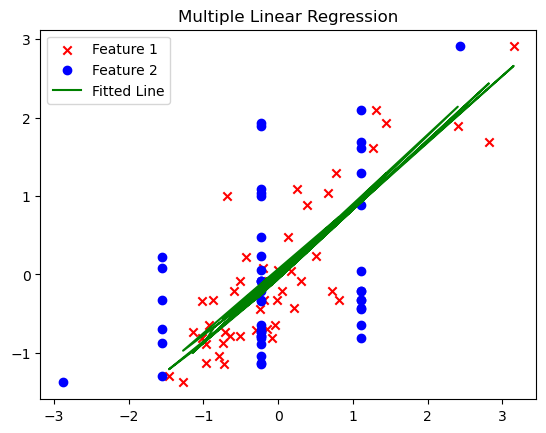

In [46]:
plt.scatter(X[:, 1], y, marker='x', c='r', label="Feature 1")
plt.scatter(X[:, 2], y, marker='o', c='b', label="Feature 2")
plt.plot(X[:, 1], pred, c='g', label="Fitted Line")
plt.title("Multiple Linear Regression")
plt.legend()
plt.show()

---
Thank You!